In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score



In [3]:
housing = pd.read_csv("housing_cleaned.csv")


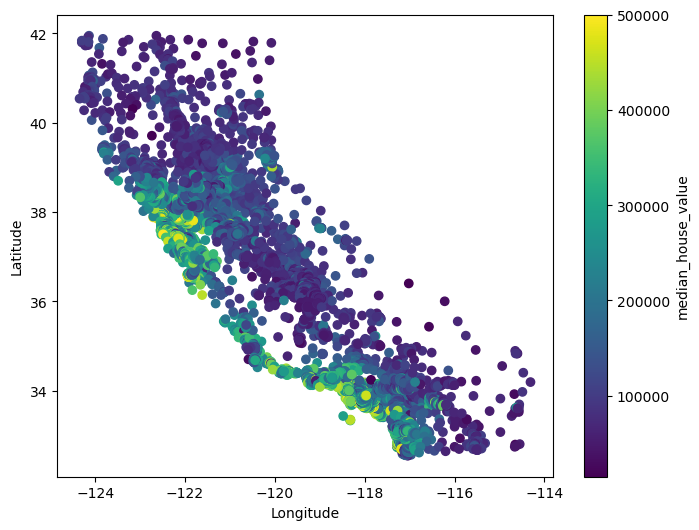

In [4]:
plt.figure(figsize=(8,6)) #h how big is the digram
plt.scatter(housing.longitude, housing.latitude, c=housing.median_house_value)
plt.ylabel("Latitude")
plt.xlabel("Longitude")
plt.colorbar(label = "median_house_value")
plt.show()

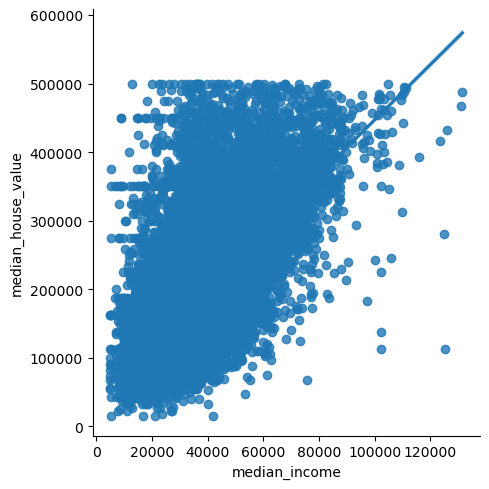

In [6]:
sns.lmplot(data=housing, x='median_income', y='median_house_value')

1. We see from EDA that the location (longitude and Latitude) are important to the median-house-value

2. The median house income is also highly correlated to the median-house-value

3. The 4 inputs (total rooms, total bedrooms, population, household) tell you the same information and not super correlated with median-house-value

4. The categorical variable of distance to ocean: Near Bay, <1H Ocean and Near ocean are similar, inland are cheap, island are expensive. So perhaps do a one hot encoding on island and inland. 

Let's do one-hot encoding on the categorical variable ocean-proximity

In [8]:
housing.ocean_proximity.unique()

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

In [12]:
housing['island'] = (housing['ocean_proximity'] == 'ISLAND').astype('int')
housing['inland'] = (housing['ocean_proximity'] == 'INLAND').astype('int')

housing.sample(7)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,island,inland
2461,-120.69,36.84,18.0,902.0,195.0,771.0,174.0,22083.0,55000.0,INLAND,0,1
10129,-117.92,33.63,39.0,1469.0,226.0,553.0,225.0,78496.0,490800.0,<1H OCEAN,0,0
6183,-118.07,34.08,38.0,2462.0,553.0,1843.0,538.0,32312.0,211900.0,<1H OCEAN,0,0
15413,-121.24,37.97,47.0,886.0,196.0,517.0,188.0,21991.0,67200.0,INLAND,0,1
14027,-117.09,32.57,23.0,1817.0,323.0,1371.0,327.0,36736.0,139500.0,NEAR OCEAN,0,0
11449,-117.20,33.71,24.0,4210.0,920.0,1283.0,829.0,20881.0,83300.0,<1H OCEAN,0,0
11579,-116.99,33.92,26.0,503.0,69.0,293.0,59.0,37083.0,147500.0,INLAND,0,1


We perform a train test split and preserve the testing dataset

Always set shuffle=True and pick a random_state so that the result is reproducable

In [14]:
housing_train, housing_test = train_test_split(housing, test_size=0.2, shuffle=True, random_state=0)

housing_train.shape, housing_test.shape

((15577, 12), (3895, 12))

We are not going touch the testing set until the model is finalized. But then how do we evaluate how each model is doing?

We do k-fold cross validation!

Within the training set, we divide it into k chuncks, have k-1 chuncks as training set and 1 chunck as the testing set.

We loop through the k chuncks, everytime set 1 chunck as the testing and the rest as training. Do the regression on them

At the end, compute average metrics (R2-score, mean-square-error etc) over the loop.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42) 
#n-splits=number of chuncks.
# kf is a generator object. Now, you give kf a dataframe, it will split it into k chuncks

Let us try different liner reg models with some subset of columns

In [18]:
housing.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity', 'island', 'inland'],
      dtype='object')

In [ ]:
feature=['median_incomee', 'latitude']

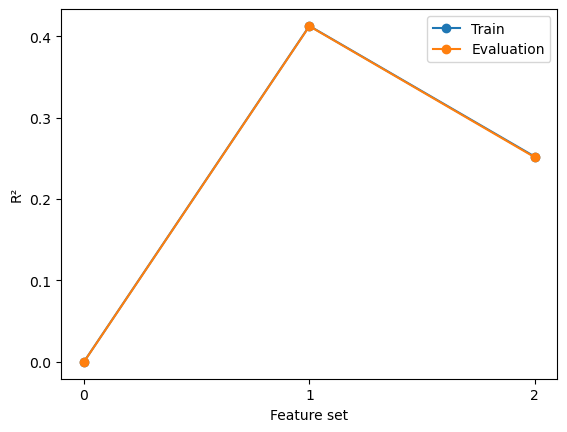

In [32]:
feat = {}

feat[0] = []
feat[1] = ['median_income']
feat[2] = ['longitude', 'latitude']


train_scores = {}
eval_scores = {}

for ii in range(3):
    train_scores[ii] = np.zeros(5)
    eval_scores[ii] = np.zeros(5)

loop =0

for train_idx, eval_idx in kf.split(housing_train):
    housing_tt = housing_train.iloc[train_idx]
    housing_eval = housing_train.iloc[eval_idx]

    y_tt = housing_tt['median_house_value']
    y_eval = housing_eval['median_house_value']

    baseline = y_tt.mean()

    train_pred = np.full(len(y_tt), baseline)
    eval_pred = np.full(len(y_eval), baseline)

    train_scores[0][loop] = r2_score(y_tt, train_pred)
    eval_scores[0][loop] = r2_score(y_eval, eval_pred)

    for ii in range(1,3):
        X_tt = housing_tt[feat[ii]]
        X_eval = housing_eval[feat[ii]]
        

        model = LinearRegression()
        model.fit(X_tt, y_tt)

        train_pred = model.predict(X_tt)
        eval_pred = model.predict(X_eval)

        train_scores[ii][loop] = r2_score(y_tt, train_pred)
        eval_scores[ii][loop] = r2_score(y_eval, eval_pred)

    loop +=1

train_r2 = [train_scores[ii].mean() for ii in range(3)]
eval_r2 = [eval_scores[ii].mean() for ii in range(3)]

# plt.figure(figsize=(12,12))
plt.plot(range(3), train_r2, 'o-', label='Train')
plt.plot(range(3), eval_r2, 'o-', label='Evaluation')

plt.xlabel('Feature set')
plt.ylabel('R²')
plt.xticks(range(3))
plt.legend()
plt.show()

Why is there only one line? Is there a bug in our code?
Let's print the training and evaluation R2 score just to be sure

In [33]:
for ii in range(3):
    train_r2 = train_scores[ii].mean()
    eval_r2 =eval_scores[ii].mean()
    print(f'For Linear Regression with {feat[ii]}, train R^2 = {train_r2: .4f} and eval R^2 = {eval_r2:.4f}')
    # .4f, 


For Linear Regression with [], train R^2 =  0.0000 and eval R^2 = -0.0002
For Linear Regression with ['median_income'], train R^2 =  0.4129 and eval R^2 = 0.4126
For Linear Regression with ['longitude', 'latitude'], train R^2 =  0.2521 and eval R^2 = 0.2514


Ha, there is no bug! And the R2 for training and evaluation are really closed.

This tells us that these models do not "overfit"

In general when you add more and more feature, performance of traning will definitely improve (why?) 

But the performance of evaluation might go down (why?) This phenomonon is called overfitting. When the number of feature is big and the number of

points are not big enough this is when overfitting happens. 

To understand why overfitting happens, let's do a thought experiment:
Imagine the extreme case where # features is >= # data points.

Lets call # features as n and # data points as m

Now, linear regression is to learn the coefficient matrix that sends input 
[x11....x1m]
[x21....x2m]
......
[xn1....xnm]

to the output
[y1.....ym]

Due to the noise, there should not exists an exact solution and linear regression learn

the approximate solution. But if n>m, then this matrix define for you an underspecficed

linear system of equation so the coefficient it learns is the exact solution, and it will memorize the noise

THen when you go to the testing/evaluation set, the noise are going to change so this solution will not give you

the right value for output.


### Overfitting

We generate data from the true relationship

\[
y = 1 - x + x^2 + \text{noise}.
\]

We then fit polynomial regression models of degree 1 through 5. As the polynomial degree increases, the model becomes more flexible.

A more flexible model usually fits the training data better, so the training \(R^2\) increases. However, after a point the model begins fitting the random noise rather than the underlying relationship. This is **overfitting**: the model performs very well on the training data but worse on new test data.

In this example, a degree-5 polynomial can fit all six training points exactly, giving training \(R^2=1\), even though it does not represent the true relationship well.

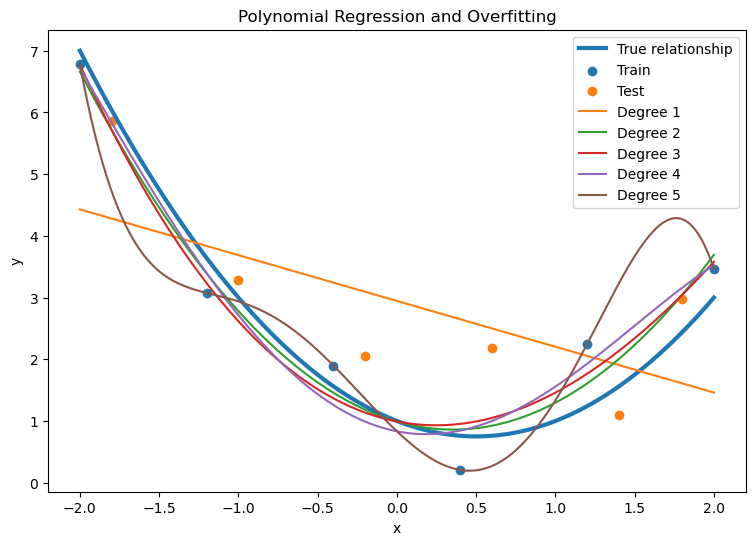

In [31]:
from sklearn.preprocessing import PolynomialFeatures



# True relationship
def f(x):
    return 1 - x + x**2


# 6 training points and 6 test points
x_train = np.array([-2, -1.2, -0.4, 0.4, 1.2, 2.0])
x_test  = np.array([-1.8, -1.0, -0.2, 0.6, 1.4, 1.8])

# Add noise
rng = np.random.default_rng(18)

y_train = f(x_train) + rng.normal(0, 0.5, 6)
y_test  = f(x_test) + rng.normal(0, 0.5, 6)


train_r2 = []
test_r2 = []

x_plot = np.linspace(-2, 2, 500)


plt.figure(figsize=(9, 6))

# True relationship and data
plt.plot(x_plot, f(x_plot), label='True relationship', linewidth=3)
plt.scatter(x_train, y_train, label='Train')
plt.scatter(x_test, y_test, label='Test')

for degree in range(1, 6):

    poly = PolynomialFeatures(degree, include_bias=False)

    X_train = poly.fit_transform(x_train.reshape(-1, 1))
    X_test = poly.transform(x_test.reshape(-1, 1))
    X_plot = poly.transform(x_plot.reshape(-1, 1))

    model = LinearRegression()
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    plot_pred = model.predict(X_plot)

    train_r2.append(r2_score(y_train, train_pred))
    test_r2.append(r2_score(y_test, test_pred))

    plt.plot(x_plot, plot_pred, label=f'Degree {degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Regression and Overfitting')
plt.legend()
plt.show()

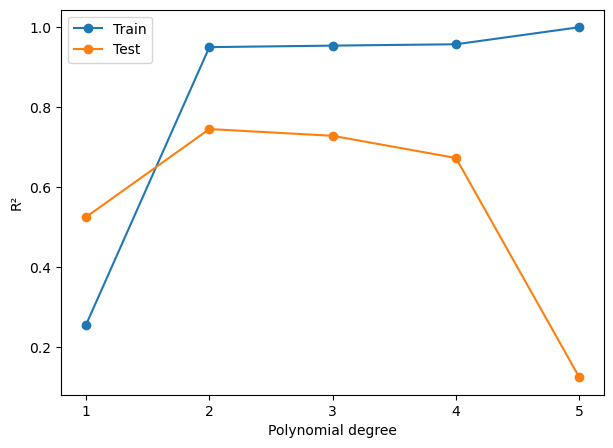

In [30]:
degrees = range(1, 6)

plt.figure(figsize=(7, 5))

plt.plot(degrees, train_r2, 'o-', label='Train')
plt.plot(degrees, test_r2, 'o-', label='Test')

plt.xlabel('Polynomial degree')
plt.ylabel('R²')
plt.xticks(degrees)
plt.legend()
plt.show()

This weeks task:

Explore more combination of features and run k-fold cross validations on those features. Find out their R2 score

Question: Should we put longnitude and latitude as they are into a linear regression?